<h1>Оценка эффективности системы рекомендаций онлайн-магазина здорового питания</h1>
<p>У магазина есть приложение, внутри которого реализована рекомендательная система: она подсказывает пользователю, какие товары ему может быть интересно добавить в корзину. Раньше система была реализована довольно прямолинейно: пользователю предлагалось добавить те товары, которые он часто покупал в прошлом.</p>
<p>Однако был разработан новый алгоритм, который теперь работает на основе ИИ и предлагает в том числе и те товары, которые раньше пользователь не покупал</p>
<p>Вопрос: <b>действительно ли новый алгоритм работает лучше, чем существующий?</b></p>
<p>Чтобы ответить на него, был проведен A/B-тест, в ходе которого контрольная группа пользователей продолжала пользоваться старой версией системы рекомендаций, а экспериментальная группа использовала новый алгоритм. <b>Период проведения A/B-теста — с 01.10.2023 по 14.10.2023 включительно</b>.</p>

<h1>Данные</h1>
<p>Таблица <b>user</b> (Общая информация о пользователях магазина)</p>
<ul>
    <li>user_id (int) - идентификатор пользователя</li>
    <li>gender (str) - пол</li>
    <li>age (int) - возраст на момент 01.09.2023</li>
    <li>region (str) - регион, в котором проживает пользователь</li>
</ul>
<p></p>
<p></p>
<p>Таблица <b>user_ab_group</b> (Информация о том, в какую группу в рамках эксперимента входил тот или иной пользователь. В эксперименте участвовали не все пользователи)</p>
<ul>
    <li>user_id  (int) - идентификатор</li>
    <li>group  (str) - - группа, в которую входит пользователь (control/treatment)
</li>
</ul>

<p>Таблица <b>user_purchase</b> (Информация о покупках, которые совершали пользователи. Также в таблице содержаться данные о покупках тех же пользователей вне A/B-эксперимента)</p>
<ul>
    <li>id (int) - идентификатор покупки</li>
    <li>user_id  (int) - идентификатор пользователя, который совершил покупку</li>
    <li>date_time  (str) - момент времени, когда была совершена покупка. Формат: “%Y-%m-%d %H:%M:%S“</li>
</ul>

<p>Таблица <b>purchase_good</b> (Информация о товарах, которые входили в список покупок, совершенных пользователями. Каждому товару из конкретной покупки соответствует отдельная строчка в таблице)</p>
<ul>
    <li>purchase_id  (int) - идентификатор покупки</li>
    <li>good_id (int) - идентификатор товара, который входит в эту покупку</li>
    <li>amount (int) - кол-во единиц товара, входящих в покупку</li>
    <li>was_in_recommended_goods (bool) - был ли приобретенный продукт добавлен в корзину по рекомендации</li>
</ul>

<p>Таблица <b>good</b> (Каталог товаров)</p>
<ul>
    <li>id (int) — идентификатор товара</li>
    <li>good_name (str) — название товара</li>
    <li>price_per_unit (число) — цена за единицу товара; валюту уточнить по источнику</li>
</ul>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

START, END = pd.Timestamp('2023-10-01'), pd.Timestamp('2023-10-15')
EXPECTED_ASSIGNED = 11_915  # Контроль исходной выгрузки, а не подставленный знаменатель.
EXPECTED_TREATMENT_SHARE = 0.5  # Подтвердить по протоколу независимой рандомизации 1:1.
ALPHA = 0.05

In [2]:
# Впишите пути к вашим исходным CSV. Пустые строки оставлены намеренно.
user = pd.read_csv('C:/Effectiveness-of-recommendation-system/data/user.csv')
user_ab_group = pd.read_csv('C:/Effectiveness-of-recommendation-system/data/user_ab_group.csv')
good = pd.read_csv('C:/Effectiveness-of-recommendation-system/data/good.csv')
user_purchase = pd.read_csv('C:/Effectiveness-of-recommendation-system/data/user_purchase.csv')
purchase_good = pd.read_csv('C:/Effectiveness-of-recommendation-system/data/purchase_good.csv')

In [3]:
user.head()

,user_id,gender,age,region
0,1,Ж,23,Краснодарский край
1,2,Ж,43,Краснодарский край
2,3,М,36,Краснодарский край
3,4,Ж,39,Краснодарский край
4,5,М,43,Иркутская область


In [4]:
user_ab_group.head()

,user_id,group
0,5034,treatment
1,4725,treatment
2,911,treatment
3,13267,control
4,5636,control


In [5]:
good.head()

,id,good_name,price_per_unit
0,1,Органический авокадо,336
1,2,Льняные семена,796
2,3,Кокосовое масло Extra Virgin,558
3,4,Гречка цельнозерновая,484
4,5,Лосось дикого копчения,480


In [6]:
user_purchase.head()

,id,user_id,date_time
0,1,5784,2023-09-20 00:01:07
1,2,4468,2023-09-20 00:04:18
2,3,3827,2023-09-20 00:04:35
3,4,3272,2023-09-20 00:06:32
4,5,9461,2023-09-20 00:08:24


In [7]:
purchase_good.head()

,purchase_id,good_id,amount,was_in_recommended_goods
0,15495,34,2,False
1,42640,48,1,False
2,42640,36,1,False
3,42640,12,2,True
4,42640,35,1,True


<h2>Обработка данных</h2>

<h4>Проверка типов данных</h4>

In [8]:
display(user.dtypes)

user_id    int64
gender       str
age        int64
region       str
dtype: object

In [9]:
display(user_ab_group.dtypes)

user_id    int64
group        str
dtype: object

In [10]:
display(good.dtypes)

id                int64
good_name           str
price_per_unit    int64
dtype: object

In [11]:
display(user_purchase.dtypes)

id           int64
user_id      int64
date_time      str
dtype: object

In [12]:
user_purchase['date_time'] = pd.to_datetime(user_purchase['date_time'],
                                           format='%Y-%m-%d %H:%M:%S')

In [13]:
display(user_purchase.dtypes)

id                    int64
user_id               int64
date_time    datetime64[us]
dtype: object

<h4>Предварительный анализ</h4>

<h5>Таблица <b>user</b></h5>

In [14]:
user['gender'].value_counts(normalize=True)

gender
Ж    0.509067
М    0.490933
Name: proportion, dtype: float64

In [15]:
user['region'].value_counts(normalize=True)

region
Краснодарский край       0.311600
Санкт-Петербург          0.231600
Иркутская область        0.148133
Нижегородская область    0.135733
Оренбургская область     0.103933
Астраханская область     0.049000
Республика Адыгея        0.020000
Name: proportion, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

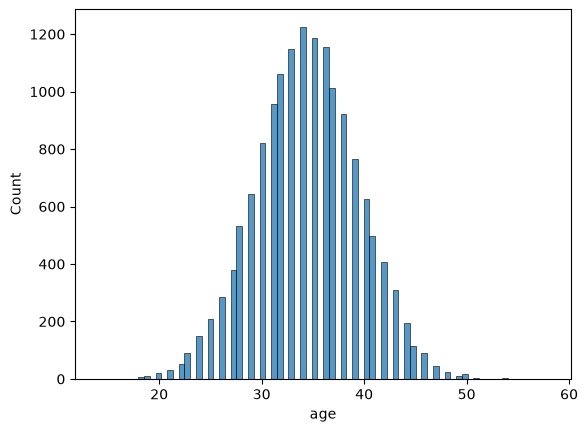

In [16]:
sns.histplot(user['age'])

In [17]:
user.describe()

,user_id,age
count,15000.000000,15000.000000
mean,7500.500000,34.429400
std,4330.271354,5.001122
min,1.000000,14.000000
25%,3750.750000,31.000000
50%,7500.500000,34.000000
75%,11250.250000,38.000000
max,15000.000000,58.000000


### Интерпретация описательной статистики
Пол, регионы и возраст описывают весь справочник пользователей, а не обязательно участников теста.
Доли и средние следует читать из пересчитанных ячеек выше; старые числовые выводы не перенесены без CSV.

<h5>Таблица <b>good</b></h5>

In [18]:
good.head()

,id,good_name,price_per_unit
0,1,Органический авокадо,336
1,2,Льняные семена,796
2,3,Кокосовое масло Extra Virgin,558
3,4,Гречка цельнозерновая,484
4,5,Лосось дикого копчения,480


In [19]:
good.describe()

,id,price_per_unit
count,100.000000,100.000000
mean,50.500000,508.860000
std,29.011492,99.104987
min,1.000000,299.000000
25%,25.750000,440.000000
50%,50.500000,496.000000
75%,75.250000,577.250000
max,100.000000,796.000000


In [20]:
good['good_name'].sort_values(ascending=True).unique()

<StringArray>
[                                        'Авокадо-масло',
                                       'Агавовый нектар',
                                     'Алоэ вера напиток',
                                    'Амарантовые хлопья',
                                        'Ананас сушёный',
                          'Арахисовая паста без добавок',
                                          'Белок гороха',
                                   'Белый чай в листьях',
                                         'Бобовые чипсы',
                                             'Бобы мунг',
                                     'Бразильские орехи',
                                       'Брокколи свежий',
                                             'Бурый рис',
                                       'Горчичное масло',
 'Горькая шоколадная плитка с высоким содержанием какао',
                            'Горький миндальный шоколад',
                            'Гранатовый сок натуральный',


In [21]:
display(good[(good['good_name'] == 'Авокадо-масло') | (good['good_name'] == 'Масло авокадо')])

,id,good_name,price_per_unit
76,77,Масло авокадо,548
90,91,Авокадо-масло,550


### Проверка похожих названий
«Масло авокадо» и «Авокадо-масло» могут обозначать разные SKU/фасовки.
Совпадение названий не доказывает дубль; ничего автоматически не объединяем и не удаляем.

In [22]:
if not (user_purchase['id'].is_unique):
    raise ValueError('Повторные purchase id')
if not (good['id'].is_unique):
    raise ValueError('Повторные good id')
a = purchase_good.merge(user_purchase.rename(columns={'id': 'purchase_id'}),
                        on='purchase_id', how='left', validate='many_to_one')
b = a.merge(good.rename(columns={'id': 'good_id'}), on='good_id', how='left', validate='many_to_one')

In [23]:
b[(b['good_name'] == 'Авокадо-масло') | (b['good_name'] == 'Масло авокадо')] \
    .sort_values('date_time', ascending=True).tail()

,purchase_id,good_id,amount,was_in_recommended_goods,user_id,date_time,good_name,price_per_unit
61307,74923,91,1,False,2589,2023-11-28 23:22:36,Авокадо-масло,550
155828,74926,91,1,False,6622,2023-11-28 23:26:58,Авокадо-масло,550
155832,74926,77,1,False,6622,2023-11-28 23:26:58,Масло авокадо,548
327150,74936,91,1,False,13917,2023-11-28 23:38:41,Авокадо-масло,550
60586,74944,91,1,True,2563,2023-11-28 23:49:39,Авокадо-масло,550


Покупки двух SKU в один день не доказывают сбой программы или переименование.
Для вывода нужна сверка каталога, состава и фасовки; эта разведка не меняет пользовательскую метрику.

<h5>Таблица <b>user_purchase</b></h5>

In [24]:
user_purchase.head()

,id,user_id,date_time
0,1,5784,2023-09-20 00:01:07
1,2,4468,2023-09-20 00:04:18
2,3,3827,2023-09-20 00:04:35
3,4,3272,2023-09-20 00:06:32
4,5,9461,2023-09-20 00:08:24


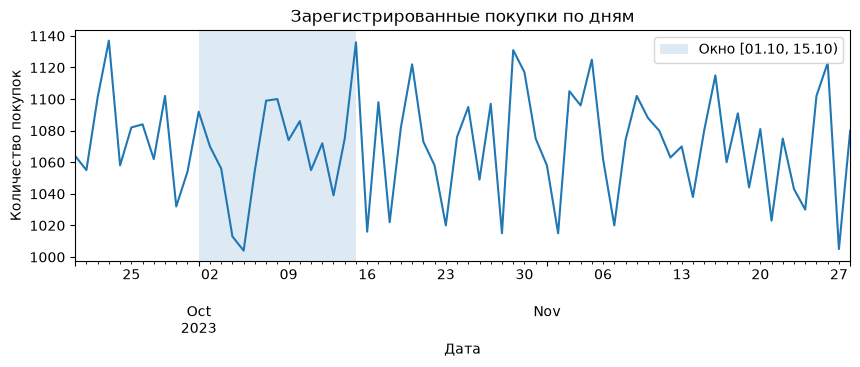

In [25]:
daily_purchases = user_purchase.groupby(user_purchase['date_time'].dt.normalize()).size()
ax = daily_purchases.plot(title='Зарегистрированные покупки по дням', figsize=(10, 3))
ax.axvspan(START, END, alpha=0.15, label='Окно [01.10, 15.10)')
ax.set_ylabel('Количество покупок'); ax.set_xlabel('Дата'); ax.legend()
plt.show()

График показывает количество зарегистрированных покупок, не выручку и не количество товаров.
Внешне ровная динамика не доказывает независимость от даты и полноту регистрации событий.

## Анализ результатов A/B-теста

<h4>Проверка разбиения пользователей на группы</h4>

In [26]:
user_purchase.groupby('user_id', as_index=False) \
            .agg({'date_time': 'count'})

,user_id,date_time
0,1,4
1,2,6
2,3,4
3,4,6
4,5,7
...,...,...
14982,14996,5
14983,14997,6
14984,14998,4
14985,14999,6


In [27]:
user_ab_group.head()

,user_id,group
0,5034,treatment
1,4725,treatment
2,911,treatment
3,13267,control
4,5636,control


In [28]:
def validate_assignments(assignments):
    groups = assignments[['user_id', 'group']].copy()
    if not (not groups.isna().any().any()):
        raise ValueError('Пропуски в назначениях')
    if not (groups['user_id'].is_unique):
        raise ValueError('Повторное назначение user_id')
    if not (set(groups['group']) == {'control', 'treatment'}):
        raise ValueError('Ожидаются control и treatment')
    return groups

assignment_base = validate_assignments(user_ab_group)
if not (len(assignment_base) == EXPECTED_ASSIGNED):
    raise ValueError(f'Ожидалось {EXPECTED_ASSIGNED} назначений, получено {len(assignment_base)}. Проверьте версию выгрузки; не сокращайте базу до покупателей.')
if not (user['user_id'].notna().all() and user['user_id'].is_unique):
    raise ValueError('Неуникальный ключ справочника user')
assignment_profiles = assignment_base.merge(user, on='user_id', how='left', validate='one_to_one', indicator=True)
print('Назначения без профиля (не исключаются из метрики):', int(assignment_profiles['_merge'].eq('left_only').sum()))
assigned_control_ids = set(assignment_base.loc[assignment_base['group'].eq('control'), 'user_id'])
assigned_treatment_ids = set(assignment_base.loc[assignment_base['group'].eq('treatment'), 'user_id'])

Назначения без профиля (не исключаются из метрики): 0


In [29]:
display(assigned_control_ids & assigned_treatment_ids)

set()

In [30]:
assignment_base['group'].value_counts().reindex(['control', 'treatment'])

group
control      5925
treatment    5990
Name: count, dtype: int64

### SRM: проверка соотношения назначений
Используем **все назначения**, а не покупателей. Биномиальный тест уместен при независимом
назначении с заранее установленной долей treatment. Для блочной/стратифицированной схемы
нужна проверка, соответствующая протоколу рандомизации.

H0: вероятность назначения в treatment равна `EXPECTED_TREATMENT_SHARE`. Двусторонняя проверка.

In [31]:
our_diff = len(assigned_treatment_ids) - len(assigned_control_ids)
display(our_diff)

65

In [32]:
rng = np.random.default_rng(2023)
# Иллюстрация нулевого распределения; численный SRM-тест — ниже.
sim_treatment = rng.binomial(len(assignment_base), EXPECTED_TREATMENT_SHARE, size=10_000)
diffs = 2 * sim_treatment - len(assignment_base)

In [33]:
diffs_s = pd.Series(diffs)
display(diffs_s)

0       -23
1       -67
2        91
3       101
4       -41
       ... 
9995    157
9996    195
9997    -37
9998      1
9999   -161
Length: 10000, dtype: int64

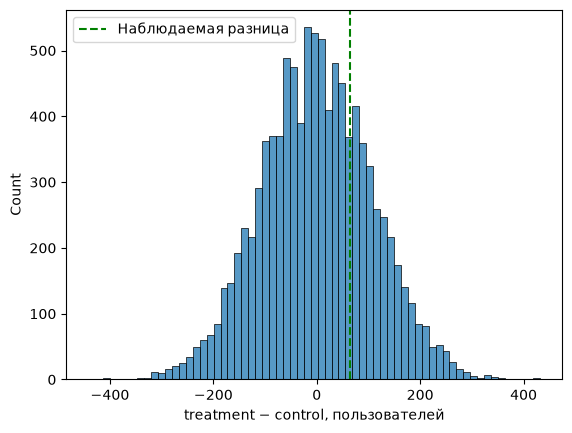

In [34]:
ax = sns.histplot(diffs_s)
ax.axvline(our_diff, linestyle='--', color='green', label='Наблюдаемая разница')
ax.set_xlabel('treatment − control, пользователей'); ax.legend()
plt.show()

In [35]:
srm_p = binomtest(len(assigned_treatment_ids), len(assignment_base),
                  p=EXPECTED_TREATMENT_SHARE, alternative='two-sided').pvalue
print(f'SRM p-value = {srm_p:.6g}')
null_interval = np.quantile(diffs_s, [ALPHA/2, 1-ALPHA/2])

SRM p-value = 0.557664


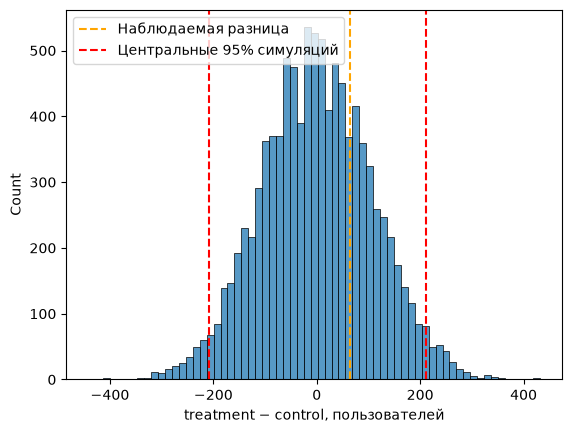

In [36]:
ax = sns.histplot(diffs_s)
ax.axvline(our_diff, linestyle='--', color='orange', label='Наблюдаемая разница')
for j, boundary in enumerate(null_interval):
    ax.axvline(boundary, linestyle='--', color='red', label='Центральные 95% симуляций' if j == 0 else None)
ax.set_xlabel('treatment − control, пользователей'); ax.legend()
plt.show()

Если SRM p-value ≥ 0,05, на выбранном уровне не обнаружено свидетельств нарушения
заданного соотношения. Это **не доказательство** корректности всей рандомизации.
При p-value < 0,05 сначала расследуйте проблему; статистический результат ниже не повод для запуска алгоритма.

#### Расчет метрики

**Метрика:** доля **всех назначенных** участников, у которых в окне
`[2023-10-01 00:00:00, 2023-10-15 00:00:00)` была хотя бы одна покупка с товаром,
добавленным по рекомендации. A = control (старый алгоритм), B = treatment (новый).

Знаменатель — таблица назначений (в исходном сохранённом анализе 11 915 строк;
уникальность теперь проверяется). 8 222 — число пользователей старой отобранной
выборки с усечённой границей дат; **не используем его как знаменатель и не требуем,
чтобы новое число покупателей ему равнялось**. Новое число наблюдаемых покупателей — только диагностика.

`max` флага вычисляется на уровне пользователя; затем **left join** к полной таблице
назначений и `fillna(False)`. Участник без покупок получает `success=False` и остаётся
в знаменателе. A = control, B = treatment.

**Допущение расчёта:** отсутствие строки в журнале за период означает отсутствие покупки;
отсутствие зарегистрированного `True` означает отсутствие успеха. Подтверждение полноты
не блокирует расчёт. Результат справедлив при полном и одинаковом наблюдении групп;
потери покупок, товарных строк или флагов могут занизить доли и исказить эффект.
Отсутствующие составы покупок и флаги показываются отдельно в диагностике, без остановки
расчёта; подставленный `False` не доказывает фактическое отсутствие события.
Таблицы профилей и каталога не определяют включение в метрику.

In [37]:
display(user)

,user_id,gender,age,region
0,1,Ж,23,Краснодарский край
1,2,Ж,43,Краснодарский край
2,3,М,36,Краснодарский край
3,4,Ж,39,Краснодарский край
4,5,М,43,Иркутская область
...,...,...,...,...
14995,14996,М,41,Нижегородская область
14996,14997,Ж,30,Астраханская область
14997,14998,М,26,Краснодарский край
14998,14999,М,36,Оренбургская область


In [38]:
user_ab_group.sort_values('user_id', ascending=True)

,user_id,group
1792,1,control
2779,2,treatment
1400,4,control
6725,6,treatment
3961,9,control
...,...,...
6666,14995,control
8897,14996,treatment
6667,14998,treatment
7913,14999,control


In [39]:
def calculate_ab(assignments, purchases, goods, *, start='2023-10-01', end='2023-10-15'):
    """Все назначения; max флага по пользователю и left join с fillna(False).

    Допущение: отсутствующие записи считаются отсутствием покупки/успеха.
    Расчёт не доказывает полноту журналов; проблемы покрытия выводятся в диагностике.
    """
    groups = validate_assignments(assignments)
    p = purchases[['id', 'user_id', 'date_time']].copy().rename(columns={'id': 'purchase_id'})
    if not (not p.isna().any().any()):
        raise ValueError('Пропуски в ключах/датах покупок')
    if not (p['purchase_id'].is_unique):
        raise ValueError('Повторные ID покупок')
    p['date_time'] = pd.to_datetime(p['date_time'], format='%Y-%m-%d %H:%M:%S', errors='raise')
    if not (p['date_time'].dt.tz is None):
        raise ValueError('Ожидается локальное время эксперимента без tz; согласуйте часовой пояс')
    if not (pd.Timestamp(start) < pd.Timestamp(end)):
        raise ValueError('Неверное окно наблюдения')
    g = goods[['purchase_id', 'good_id', 'amount', 'was_in_recommended_goods']].copy()
    if not (not g[['purchase_id', 'good_id', 'amount']].isna().any().any()):
        raise ValueError('Пропуски в ключах/количестве товарных строк')
    if not (pd.api.types.is_numeric_dtype(g['amount']) and (g['amount'] > 0).all()):
        raise ValueError('amount должен быть числом > 0')
    if not (g['purchase_id'].isin(p['purchase_id']).all()):
        raise ValueError('Товарные строки с неизвестной покупкой')
    # Явное преобразование, НЕ astype(bool) для строк False/True.
    def parse_flag(x):
        if pd.isna(x):
            return pd.NA
        if isinstance(x, (bool, np.bool_)):
            return bool(x)
        if isinstance(x, str) and x in {'True', 'False', 'true', 'false'}:
            return x.lower() == 'true'
        raise ValueError(f'Неизвестное значение флага: {x!r}')
    g['was_in_recommended_goods'] = g['was_in_recommended_goods'].map(parse_flag).astype('boolean')
    # Сначала окно, затем только назначенные участники. Назначения не сокращаем.
    period_purchases = p.loc[p['date_time'].ge(pd.Timestamp(start)) & p['date_time'].lt(pd.Timestamp(end))]
    period_purchases = period_purchases.merge(groups, on='user_id', how='inner', validate='many_to_one')
    period_lines = period_purchases.merge(g, on='purchase_id', how='left',
                                         validate='one_to_many', indicator=True)
    missing_orders = period_lines.loc[period_lines['_merge'].eq('left_only'), 'purchase_id'].nunique()
    unknown_flags = int((period_lines['_merge'].eq('both') &
                         period_lines['was_in_recommended_goods'].isna()).sum())
    # max(True, False) -> True. Отсутствующий исход после left join станет False
    # по явно принятому допущению, а не по результату проверки полноты.
    observed = (period_lines.groupby('user_id', as_index=False)['was_in_recommended_goods']
                .max().rename(columns={'was_in_recommended_goods': 'observed_max'}))
    result = groups.merge(observed, on='user_id', how='left', validate='one_to_one')
    result['observed_max'] = result['observed_max'].astype('boolean')
    result['has_observed_purchase'] = result['user_id'].isin(period_purchases['user_id'])
    result['success'] = result['observed_max'].fillna(False).astype(bool)
    result['outcome_status'] = np.where(result['success'], 'success', 'no_registered_success')
    if not (len(result) == len(groups) and result['user_id'].is_unique):
        raise ValueError('Потеря/размножение назначений')
    summary = result.groupby('group').agg(
        users=('user_id', 'size'), successes=('success', 'sum')
    ).reindex(['control', 'treatment'])
    summary['failures'] = summary['users'] - summary['successes']
    summary['rate'] = summary['successes'] / summary['users']
    diagnostics = {
        'assigned_users': len(groups),
        'observed_purchase_users': int(result['has_observed_purchase'].sum()),
        'users_without_purchases_assigned_false': int((~result['has_observed_purchase']).sum()),
        'orders_without_goods': int(missing_orders), 'rows_with_unknown_flag': unknown_flags,
        'duplicate_purchase_good_pairs': int(g.duplicated(['purchase_id', 'good_id']).sum()),
        'missing_outcomes_filled_false': int(result['observed_max'].isna().sum()),
        'assumption': 'Отсутствие записи означает отсутствие покупки/успеха; результат зависит от полноты источника.',
    }
    return result, summary, diagnostics, period_purchases, period_lines


d1, d2, diagnostics, period_purchases, period_lines = calculate_ab(
    assignment_base, user_purchase, purchase_good, start=START, end=END,
)
# d1: все назначенные, success — bool без пропусков. d2: доли по полным группам.
if len(d1) != len(assignment_base) or d1['success'].isna().any():
    raise ValueError('Нарушена база назначений или бинарность исхода')
display(pd.Series(diagnostics, name='diagnostics'))

assigned_users                                                                        11915
observed_purchase_users                                                                8578
users_without_purchases_assigned_false                                                 3337
orders_without_goods                                                                      0
rows_with_unknown_flag                                                                    0
duplicate_purchase_good_pairs                                                          3554
missing_outcomes_filled_false                                                          3337
assumption                                Отсутствие записи означает отсутствие покупки/...
Name: diagnostics, dtype: object

In [40]:
display(d1.head())
print('Назначенных пользователей:', len(d1))

,user_id,group,observed_max,has_observed_purchase,success,outcome_status
0,5034,treatment,<NA>,False,False,no_registered_success
1,4725,treatment,True,True,True,success
2,911,treatment,True,True,True,success
3,13267,control,True,True,True,success
4,5636,control,<NA>,False,False,no_registered_success


Назначенных пользователей: 11915


In [41]:
display(period_purchases.head())
print('Наблюдаемые пользователи с покупками за полное окно:', diagnostics['observed_purchase_users'])

,purchase_id,user_id,date_time,group
0,11833,12987,2023-10-01 00:02:30,treatment
1,11834,5026,2023-10-01 00:02:46,control
2,11836,4791,2023-10-01 00:07:04,treatment
3,11837,6773,2023-10-01 00:07:21,treatment
4,11838,10438,2023-10-01 00:07:25,control


Наблюдаемые пользователи с покупками за полное окно: 8578


In [42]:
# Окно уже применено ДО соединения товаров; весь день 14 октября включён.
ab_result_table = period_lines

In [43]:
ab_result_table.head()

,purchase_id,user_id,date_time,group,good_id,amount,was_in_recommended_goods,_merge
0,11833,12987,2023-10-01 00:02:30,treatment,14,1,False,both
1,11833,12987,2023-10-01 00:02:30,treatment,11,1,False,both
2,11833,12987,2023-10-01 00:02:30,treatment,27,1,False,both
3,11833,12987,2023-10-01 00:02:30,treatment,53,1,False,both
4,11834,5026,2023-10-01 00:02:46,control,82,1,True,both


In [44]:
# Отдельные имена: множества исходных назначений не переопределяются.
observed_purchase_user_ids = set(period_purchases['user_id'])
print('Купившие / назначенные:', len(observed_purchase_user_ids), '/', len(assignment_base))

Купившие / назначенные: 8578 / 11915


In [45]:
# Метрика по всем назначенным, в том числе пользователям без покупок (False).
display(d2)

,users,successes,failures,rate
group,,,,
control,5925,3132,2793,0.528608
treatment,5990,3916,2074,0.653756


In [46]:
d1.head(10)

,user_id,group,observed_max,has_observed_purchase,success,outcome_status
0,5034,treatment,<NA>,False,False,no_registered_success
1,4725,treatment,True,True,True,success
2,911,treatment,True,True,True,success
3,13267,control,True,True,True,success
4,5636,control,<NA>,False,False,no_registered_success
5,5625,treatment,True,True,True,success
6,1678,treatment,True,True,True,success
7,12191,treatment,True,True,True,success
8,6959,control,False,True,False,no_registered_success
9,9527,control,<NA>,False,False,no_registered_success


In [47]:
display(d2)

,users,successes,failures,rate
group,,,,
control,5925,3132,2793,0.528608
treatment,5990,3916,2074,0.653756


In [48]:
for label, group_name in [('A', 'control'), ('B', 'treatment')]:
    row = d2.loc[group_name]
    print(f'{label} = {group_name}: назначено {int(row.users)}, успехов {int(row.successes)}, без зарегистрированного успеха {int(row.failures)}')
    print(f'  Метрика: {row.rate:.6%}')

A = control: назначено 5925, успехов 3132, без зарегистрированного успеха 2793
  Метрика: 52.860759%
B = treatment: назначено 5990, успехов 3916, без зарегистрированного успеха 2074
  Метрика: 65.375626%


### Сравнение долей: z-тест и доверительные интервалы

In [49]:
print('Допущение:', diagnostics['assumption'])
if diagnostics['orders_without_goods'] or diagnostics['rows_with_unknown_flag']:
    print('ВНИМАНИЕ: есть покупки без состава или неизвестные флаги. Расчёт выполнен по допущению; прежде чем принимать решение, проверьте источник.')

Допущение: Отсутствие записи означает отсутствие покупки/успеха; результат зависит от полноты источника.


In [50]:
def compare_groups(summary, alpha=0.05):
    """Двусторонний z-тест равенства долей; A=control, B=treatment."""
    nc, nt = (int(summary.loc[k, 'users']) for k in ['control', 'treatment'])
    xc, xt = (int(summary.loc[k, 'successes']) for k in ['control', 'treatment'])
    pc, pt = xc / nc, xt / nt
    pooled = (xc + xt) / (nc + nt)
    ci = confint_proportions_2indep(xt, nt, xc, nc, compare='diff', method='newcomb', alpha=alpha)
    # Проверка применимости нормальной аппроксимации по ожидаемым частотам.
    z_appropriate = min(nc * pooled, nc * (1-pooled), nt * pooled, nt * (1-pooled)) >= 5
    if z_appropriate:
        z, pvalue = proportions_ztest([xc, xt], [nc, nt], alternative='two-sided')
    else:
        z, pvalue = np.nan, np.nan
    out = {'status': 'ok' if z_appropriate else 'small_counts', 'control_rate': pc,
           'treatment_rate': pt, 'difference_pp': (pt-pc)*100,
           'difference_ci_pp': tuple(v*100 for v in ci),
           'relative_uplift_pct': (pt/pc-1)*100 if pc > 0 else np.nan,
           'z_control_minus_treatment': z, 'pvalue_two_sided': pvalue, 'alpha': alpha}
    if xc > 0 and xt > 0:
        rr = confint_proportions_2indep(xt, nt, xc, nc, compare='ratio', method='log', alpha=alpha)
        out['relative_uplift_ci_pct'] = tuple((v-1)*100 for v in rr)
    return out

# Используется единая функция, без ручных констант A/B.
comparison = compare_groups(d2, alpha=ALPHA)
display(pd.Series(comparison, name='comparison'))

status                                           ok
control_rate                               0.528608
treatment_rate                             0.653756
difference_pp                             12.514867
difference_ci_pp             (10.758597, 14.260268)
relative_uplift_pct                       23.675155
z_control_minus_treatment                -13.895277
pvalue_two_sided                                0.0
alpha                                          0.05
relative_uplift_ci_pct       (19.984526, 27.479304)
Name: comparison, dtype: object

In [51]:
print(f"Разница B − A: {comparison['difference_pp']:.4f} п.п.")
print('95% ДИ разницы, п.п.:', comparison['difference_ci_pp'])
print(f"Относительное изменение: {comparison['relative_uplift_pct']:.4f}%")
if comparison['status'] == 'small_counts':
    print('Нормальная аппроксимация ненадёжна: z-тест не выполнен; нужен точный тест/план анализа.')
else:
    print(f"z (A − B) = {comparison['z_control_minus_treatment']:.6f}")
    print(f"Двусторонний p-value = {comparison['pvalue_two_sided']:.6e}")
    if srm_p < ALPHA:
        print('Обнаружен SRM: прежде чем интерпретировать результат, проверьте рандомизацию.')
    elif comparison['pvalue_two_sided'] < ALPHA:
        print('Есть свидетельства различия долей. Направление эффекта определяется знаком B − A.')
    else:
        print('Недостаточно оснований отвергнуть равенство долей; это не доказательство равенства.')
print("Расчёт выполнен при допущении полноты источника; статистическая значимость не подтверждает полноту данных.")

Разница B − A: 12.5149 п.п.
95% ДИ разницы, п.п.: (np.float64(10.758597013414004), np.float64(14.260267791416764))
Относительное изменение: 23.6752%
z (A − B) = -13.895277
Двусторонний p-value = 6.766109e-44
Есть свидетельства различия долей. Направление эффекта определяется знаком B − A.
Расчёт выполнен при допущении полноты источника; статистическая значимость не подтверждает полноту данных.


#### Вывод и ограничения
При уровне значимости α = 0,05 нулевая гипотеза о равенстве долей отвергается: между группами есть статистически значимое различие (двусторонний p-value = 6,77 × 10⁻⁴⁴). Метрика в группе B выше группы A на 12,51 процентного пункта. 95% доверительный интервал разницы составляет от 10,76 до 14,26 п.п. Относительное увеличение метрики — 23,68%